# Portafolio Cuantitativo Neutral al Mercado

## Extensión: Amplitud — Muchas Canastas, Selección Dentro de Cada Ventana

**Autor:** Samuel

**Institución:** Tec de Monterrey

**Área:** Finanzas Cuantitativas, Economía Estadística y Machine Learning

**Notebooks previos:** `Backtest-Corregido.ipynb` (contabilidad corregida), `Beta-Anclado-OU.ipynb` y `Remuestreo-Costos.ipynb` (reducción de rotación y costos)

---

Este notebook parte de la conclusión de los anteriores: con contabilidad corregida, la canasta USDCAD/USDNOK/USDSEK/USDSGD tiene una señal bruta significativa pero pequeña (~2% anual) que los costos consumen, y reducir la rotación, remuestrear a 4h/8h o afinar umbrales no cambió el neto (≈ 0). El límite no está en el ajuste sino en el número de apuestas independientes (~20 operaciones por configuración).

**Pregunta:** ¿un borde pequeño repetido en muchas canastas poco correlacionadas puede producir un neto positivo? La selección de canastas se hace **dentro de cada ventana de walk-forward y solo con datos de entrenamiento**, y todo el proceso se valida con placebo.

## Estructura de este Notebook

1. **Instalación de librerías** — las mismas de los notebooks previos (`numba` muy recomendado aquí).
2. **Fase 1: Datos** — *ampliada*. 18 divisas con verificación de nivel de precio y cobertura.
3. **Fase 2: Canastas candidatas y dependencia del universo** — *nueva*. 4,029 canastas; el universo tiene ~13 residuos independientes tras quitar 1 a 3 factores.
4. **Fase 3: Motor por spread** — *reutilizada* de `Beta-Anclado-OU.ipynb`, generalizada: recibe cualquier vector de pesos sobre log-precios. Es el mismo motor para las dos rutas.
5. **Fase 4: Ruta B — residuos de factores** — *nueva*. Cada divisa menos sus primeros k factores, como un spread con pesos congelados por ventana (Avellaneda y Lee, 2010).
6. **Fase 5: Ruta A — canastas cointegradas** — *nueva*. Prefiltro + cointegración con corrección FDR dentro de cada ventana, mismo motor.
7. **Fase 6: Comparación A vs. B y placebo** — misma ventana, mismos costos; número de apuestas independientes y neto.
8. **Conclusión**.

## Instalación de Librerías

Mismas librerías de `K-D.ipynb` y `Beta-Anclado-OU.ipynb`. `numba` es opcional pero acelera mucho la máquina de estados.

In [2]:
# Fase 1 — Datos
# %pip install yfinance pandas numpy

# Fase 3 — Cointegración y corrección por pruebas múltiples
# %pip install scipy statsmodels

# Fase 4 — Motor (opcional, acelera ~50x)
# %pip install numba

## Fase 1: Datos

Mismo universo base que `main.ipynb`, ampliado con divisas de otros bloques económicos. Dos cambios frente a los notebooks previos: (1) se renombra por **ticker** y no por posición (lección de `Backtest-Corregido.ipynb`: yfinance devuelve las columnas en orden alfabético), y (2) las divisas nuevas se aceptan solo si tienen cobertura horaria suficiente, porque no todas la tienen en Yahoo.

In [3]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [4]:
pd.set_option('display.max_columns', None)

base = ['EURUSD','GBPUSD','AUDUSD','NZDUSD','USDJPY','USDCAD',
        'USDCHF','USDMXN','USDCNY','USDSEK','USDNOK','USDSGD']
nuevas = ['USDZAR','USDBRL','USDINR','USDKRW','USDPLN','USDHUF','USDCZK','USDILS','USDTHB']

tickers = {k: f'{k}=X' for k in base + nuevas}

raw_close = yf.download(list(tickers.values()), period='729d', interval='60m', progress=False)['Close']
ticker_to_name = {v: k for k, v in tickers.items()}
raw_data = raw_close.rename(columns=ticker_to_name)

print(f"Descargado: {raw_data.shape}")

Descargado: (17401, 21)


In [5]:
# Cobertura: fracción de barras horarias con dato, respecto a la divisa con más datos
cobertura = raw_data.notna().mean() / raw_data.notna().mean().max()
print(cobertura.sort_values().round(3))

MIN_COBERTURA = 0.90
aceptadas = cobertura[cobertura >= MIN_COBERTURA].index.tolist()
descartadas = [c for c in tickers if c not in aceptadas]
print(f"\nAceptadas ({len(aceptadas)}): {aceptadas}")
print(f"Descartadas por cobertura ({len(descartadas)}): {descartadas}")

Ticker
USDBRL    0.681
USDCNY    0.771
USDINR    0.817
USDKRW    0.951
USDILS    0.965
USDSEK    0.977
USDTHB    0.985
USDNOK    0.989
USDJPY    0.989
USDCHF    0.991
USDSGD    0.994
EURUSD    0.994
GBPUSD    0.994
USDMXN    0.995
USDZAR    0.998
AUDUSD    0.998
NZDUSD    0.998
USDPLN    0.998
USDCAD    0.998
USDHUF    1.000
USDCZK    1.000
dtype: float64

Aceptadas (18): ['AUDUSD', 'EURUSD', 'GBPUSD', 'NZDUSD', 'USDCAD', 'USDCHF', 'USDCZK', 'USDHUF', 'USDILS', 'USDJPY', 'USDKRW', 'USDMXN', 'USDNOK', 'USDPLN', 'USDSEK', 'USDSGD', 'USDTHB', 'USDZAR']
Descartadas por cobertura (3): ['USDCNY', 'USDBRL', 'USDINR']


In [6]:
data = raw_data[aceptadas].ffill().dropna()

# Rangos aproximados — ajústalos si alguna divisa queda fuera por una razón legítima
expected = {'EURUSD':(0.9,1.4),'GBPUSD':(1.0,1.6),'AUDUSD':(0.5,0.9),'NZDUSD':(0.5,0.8),
            'USDJPY':(100,175),'USDCAD':(1.1,1.6),'USDCHF':(0.7,1.1),'USDMXN':(14,26),
            'USDCNY':(6.3,7.6),'USDSEK':(8,12),'USDNOK':(8,12.5),'USDSGD':(1.1,1.6),
            'USDZAR':(12,24),'USDBRL':(4,7),'USDINR':(75,100),'USDKRW':(1100,1700),
            'USDPLN':(3.3,4.8),'USDHUF':(280,430),'USDCZK':(19,27),'USDILS':(3,4.3),'USDTHB':(28,42)}

chk = pd.DataFrame({'media': data.mean(), 'min': data.min(), 'max': data.max()})
chk['ok'] = [expected[c][0] <= chk.loc[c, 'media'] <= expected[c][1] for c in chk.index]
display(chk.round(4))
print(data.shape, data.index.min(), '->', data.index.max())
assert chk['ok'].all(), "Algún nivel de precio no corresponde a su nombre (o el rango esperado hay que ajustarlo)"

,media,min,max,ok
Ticker,,,,
AUDUSD,0.6671,0.5952,0.7273,True
EURUSD,1.1216,1.0196,1.2047,True
GBPUSD,1.3118,1.2108,1.3850,True
NZDUSD,0.5903,0.5512,0.6376,True
USDCAD,1.3854,1.3352,1.4781,True
USDCHF,0.8390,0.7609,0.9222,True
USDCZK,22.0902,20.1080,24.7250,True
USDHUF,347.3083,300.1800,406.1000,True
USDILS,3.4151,2.7993,3.8435,True


(17401, 18) 2024-01-11 00:00:00+00:00 -> 2026-10-27 00:00:00+00:00


In [7]:
nombres = {
    'EURUSD': 'Euro',        'GBPUSD': 'Libra',       'AUDUSD': 'Dolar_AUS',   'NZDUSD': 'Dolar_NZ',
    'USDCAD': 'Dolar_CAN',   'USDCHF': 'Franco_SUI',  'USDCZK': 'Corona_CZ',   'USDHUF': 'Forinto_HU',
    'USDILS': 'Shekel_IL',   'USDJPY': 'Yen',         'USDKRW': 'Won_KR',      'USDMXN': 'Peso_MX',
    'USDNOK': 'Corona_NO',   'USDPLN': 'Zloty_PL',    'USDSEK': 'Corona_SE',   'USDSGD': 'Dolar_SG',
    'USDTHB': 'Baht_TH',     'USDZAR': 'Rand_ZA',
}
# Documenta la dirección de cada cotización (no cambia los datos)
cotizacion = {nombres[t]: ('USD por unidad' if t.endswith('USD') else 'unidades por USD') for t in nombres}

data_t = data.copy()          # versión con tickers, por si hay que compararla con los notebooks previos
data = data_t.rename(columns=nombres)
print(pd.Series(cotizacion))

Euro            USD por unidad
Libra           USD por unidad
Dolar_AUS       USD por unidad
Dolar_NZ        USD por unidad
Dolar_CAN     unidades por USD
Franco_SUI    unidades por USD
Corona_CZ     unidades por USD
Forinto_HU    unidades por USD
Shekel_IL     unidades por USD
Yen           unidades por USD
Won_KR        unidades por USD
Peso_MX       unidades por USD
Corona_NO     unidades por USD
Zloty_PL      unidades por USD
Corona_SE     unidades por USD
Dolar_SG      unidades por USD
Baht_TH       unidades por USD
Rand_ZA       unidades por USD
dtype: str


## Fase 2: Canastas Candidatas y Dependencia del Universo

Se enumeran todas las canastas de 2 a 4 activos. Ninguna se da por válida: es el espacio de búsqueda, y cada ventana de walk-forward elegirá entre ellas solo con su entrenamiento. Antes de seleccionar, se mide cuánta independencia real hay en el universo: si casi todas las divisas se mueven con un solo factor (el dólar), las canastas serán muchas pero las apuestas independientes, pocas.

In [8]:
from itertools import combinations

assets = list(data.columns)
baskets = [c for k in (2, 3, 4) for c in combinations(assets, k)]
conteo = {k: sum(len(b) == k for b in baskets) for k in (2, 3, 4)}
print(f"{len(baskets)} canastas candidatas | por tamaño: {conteo}")

4029 canastas candidatas | por tamaño: {2: 153, 3: 816, 4: 3060}


Varianza explicada por el 1er factor: 55.1%
Varianza explicada por los 3 primeros: 67.5%
Número efectivo de factores independientes: 3.1 (de 18 divisas)


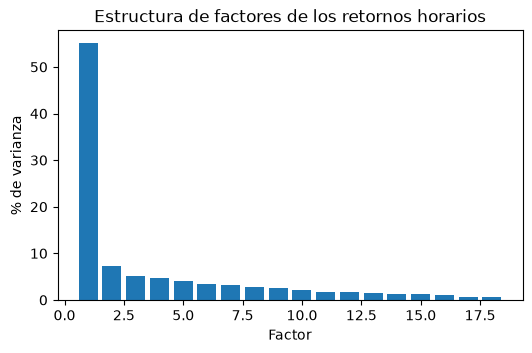

In [9]:
ret = np.log(data).diff().dropna()
corr = ret.corr()

eig = np.linalg.eigvalsh(corr.values)[::-1]          # autovalores de mayor a menor
var_exp = eig / eig.sum()
n_efectivo = eig.sum()**2 / (eig**2).sum()            # "número efectivo" de factores independientes

print(f"Varianza explicada por el 1er factor: {var_exp[0]*100:.1f}%")
print(f"Varianza explicada por los 3 primeros: {var_exp[:3].sum()*100:.1f}%")
print(f"Número efectivo de factores independientes: {n_efectivo:.1f} (de {len(assets)} divisas)")

plt.figure(figsize=(6, 3.5))
plt.bar(range(1, len(eig) + 1), var_exp * 100)
plt.xlabel("Factor"); plt.ylabel("% de varianza")
plt.title("Estructura de factores de los retornos horarios")
plt.show()

### Independencia de los residuos

El número efectivo de factores de los retornos (3.1) mide cuántas apuestas direccionales independientes hay. Una canasta market-neutral cancela el factor común, así que lo relevante es la independencia de lo que **queda después de quitar los primeros k factores**. Se mide para k = 0, 1, 2, 3, 4.

In [10]:
def n_efectivo_residual(retornos, k):
    X = ((retornos - retornos.mean()) / retornos.std()).values
    U, S, Vt = np.linalg.svd(X, full_matrices=False)
    residuo = X - (U[:, :k] * S[:k]) @ Vt[:k] if k > 0 else X
    eigs = np.linalg.eigvalsh(np.corrcoef(residuo.T))
    return eigs.sum()**2 / (eigs**2).sum()

for k in range(0, 5):
    print(f"k = {k} factores removidos -> número efectivo de residuos independientes: {n_efectivo_residual(ret, k):.1f}")

k = 0 factores removidos -> número efectivo de residuos independientes: 3.1
k = 1 factores removidos -> número efectivo de residuos independientes: 12.6
k = 2 factores removidos -> número efectivo de residuos independientes: 13.0
k = 3 factores removidos -> número efectivo de residuos independientes: 12.4
k = 4 factores removidos -> número efectivo de residuos independientes: 11.7


## Fase 3: Motor por Spread

Mismo motor de `Beta-Anclado-OU.ipynb` (β anclado + umbrales OU con costo + abstención), generalizado: un spread es cualquier combinación `s = log-precios @ w` con pesos `w` congelados en la ventana de prueba. El retorno se normaliza por la exposición bruta `Σ|w|` (en unidades de log-precio) y el costo es 1 pb por pata por lado, de modo que una canasta de 4 activos y un residuo con 18 patas son comparables.

In [11]:
from scipy import stats
from scipy.signal import lfilter
try:
    from numba import njit
except ImportError:
    njit = lambda f: f      # sin numba funciona, pero MUY lento en las Fases 4-6

TEST_DAYS, TRAIN_DAYS, MIN_TRAIN = 30, 120, 240
STOP, HL_MAX = 3.5, 24 * 15      # stop en sigmas; vida media máxima aceptada (barras horarias)
COST_BPS = 1.0

In [12]:
def fit_ou(s):
    x, y = s[:-1], s[1:]
    b, a = np.polyfit(x, y, 1)
    if not (0.0 < b < 1.0):
        return None
    r = y - (a + b * x)
    return dict(b=b, mu=a / (1 - b), sig=r.std(ddof=2) / np.sqrt(1 - b * b), hl=np.log(2) / (-np.log(b)))

@njit
def positions_from_z(z, k, e, stop):
    n = len(z); pos = np.zeros(n); p = 0.0; blocked = 0.0
    for t in range(n):
        zt = z[t]
        if blocked != 0.0 and abs(zt) < k:
            blocked = 0.0
        if p == 0.0:
            if blocked == 0.0:
                if zt >= k: p = -1.0
                elif zt <= -k: p = 1.0
        else:
            if p < 0 and zt <= e: p = 0.0
            elif p > 0 and zt >= -e: p = 0.0
            elif abs(zt) >= stop:
                blocked = 1.0 if zt > 0 else -1.0
                p = 0.0
        pos[t] = p
    return pos

In [13]:
def ou_band_search(b, c_side_z, n=40000, seed=0, ks=np.arange(0.75, 3.01, 0.25), es=(0.0, 0.25, 0.5, 1.0)):
    eps = np.random.default_rng(seed).standard_normal(n) * np.sqrt(1 - b * b)
    z = lfilter([1.0], [1.0, -b], eps); dz = np.diff(z); best = None
    for k in ks:
        for e in es:
            if e >= k: continue
            pos = positions_from_z(z, k, e, STOP)
            rate = ((pos[:-1] * dz).sum() - c_side_z * np.abs(np.diff(pos, prepend=0.0)).sum()) / n
            if best is None or rate > best[2]:
                best = (k, e, rate)
    return best if best and best[2] > 0 else None      # None = abstenerse

def run_spread(Lp_tr, Lp_te, w, cost_bps=COST_BPS, mode='ou', fixed_ke=(2.0, 0.5), seed=0):
    """Opera un spread s = log-precios @ w con pesos congelados. None si se abstiene."""
    s_tr, s_te = Lp_tr @ w, Lp_te @ w
    ou = fit_ou(s_tr)
    if ou is None or ou['hl'] > HL_MAX:
        return None
    E = np.abs(w).sum()                                    # exposición bruta
    if mode == 'fixed':
        k, e = fixed_ke
    else:
        res = ou_band_search(ou['b'], (cost_bps / 1e4) * E / ou['sig'], seed=seed)
        if res is None:
            return None
        k, e = res[0], res[1]
    pos = positions_from_z((s_te - ou['mu']) / ou['sig'], k, e, STOP)
    gross = (pos[:-1] * np.diff(s_te)).sum()
    cost = np.abs(np.diff(pos, prepend=0.0)).sum() * E * cost_bps / 1e4
    ops = int(((pos[1:] != 0) & (pos[:-1] == 0)).sum() + (pos[0] != 0))
    return dict(gross=gross / E, cost=cost / E, net=(gross - cost) / E, ops=ops, k=k, e=e, hl=ou['hl'])

## Fase 4: Ruta B — Residuos de Factores

Idea (Avellaneda y Lee, 2010): los primeros k factores de los retornos (el primero es el dólar) mueven casi todo a la vez. Lo que queda de cada divisa **después de quitarlos** es un residuo que puede revertir a su media. Con la proyección ortogonal `M = I − V Vᵀ` (V = k primeros autovectores de la correlación del entrenamiento), el residuo de la divisa i es la columna i de `M`, y como cada residuo es una combinación lineal de log-precios, entra directo al motor de la Fase 3 con pesos congelados. Son 18 spreads (uno por divisa), sin enumerar canastas ni correr pruebas de cointegración.

In [14]:
def pesos_residuo(R_train, k):
    """Columna i = pesos (sobre log-precios) del residuo de la divisa i tras quitar los k primeros factores."""
    sd = R_train.std(0)
    Z = (R_train - R_train.mean(0)) / sd
    vals, vecs = np.linalg.eigh(np.corrcoef(Z.T))
    V = vecs[:, ::-1][:, :k]                       # k autovectores con mayor autovalor
    M = np.eye(R_train.shape[1]) - V @ V.T
    return M / sd[:, None]

def ventanas(index, train_days=TRAIN_DAYS):
    day = index.normalize().values; ud = np.unique(day)
    for j in range(MIN_TRAIN, len(ud) - TEST_DAYS + 1, TEST_DAYS):
        tr = (day >= ud[j - train_days]) & (day < ud[j])
        te = (day >= ud[j]) & (day < ud[j + TEST_DAYS])
        yield j, tr, te

In [15]:
def run_ruta_B(data, k=2, mode='ou', cost_bps=COST_BPS, train_days=TRAIN_DAYS, seed=0):
    Lp = np.log(data).values
    R = np.diff(Lp, axis=0, prepend=Lp[:1])
    rows = []
    for j, tr, te in ventanas(data.index, train_days):
        W = pesos_residuo(R[tr], k)                  # pesos calibrados SOLO con el entrenamiento
        res = [run_spread(Lp[tr], Lp[te], W[:, i], cost_bps, mode, seed=seed) for i in range(W.shape[1])]
        ok = [r for r in res if r is not None]
        n_tot = W.shape[1]
        rows.append(dict(window=j, gross=sum(r['gross'] for r in ok) / n_tot,
                         cost=sum(r['cost'] for r in ok) / n_tot, net=sum(r['net'] for r in ok) / n_tot,
                         ops=sum(r['ops'] for r in ok), n_spreads=len(ok), n_tot=n_tot))
    return pd.DataFrame(rows)

def summarize(res, label):
    g, n = res.gross, res.net
    be = g.mean() / res.cost.mean() if res.cost.mean() > 0 else np.nan
    return pd.Series({'bruto': g.mean(), 'p_bruto': stats.ttest_1samp(g, 0).pvalue,
                      'neto': n.mean(), 'p_neto': stats.ttest_1samp(n, 0).pvalue,
                      'neto>0': f"{(n > 0).sum()}/{len(n)}", 'spreads/vent': res.n_spreads.mean(),
                      'ops/vent': res.ops.mean(), 'break-even (x costo)': be}, name=label)

In [16]:
rows = []
for k in (1, 2, 3):
    for mode in ('fixed', 'ou'):
        rows.append(summarize(run_ruta_B(data, k=k, mode=mode), f'B_k{k}_{mode}'))
tabla_B = pd.DataFrame(rows)
display(tabla_B)

,bruto,p_bruto,neto,p_neto,neto>0,spreads/vent,ops/vent,break-even (x costo)
B_k1_fixed,-0.000396,0.169249,-0.000473,0.111346,3/16,11.6250,8.8750,-5.130905
B_k1_ou,-0.000122,0.826448,-0.000293,0.597578,7/16,11.6250,19.0625,-0.710206
B_k2_fixed,-0.000326,0.164011,-0.000406,0.094323,3/16,12.3125,9.0000,-4.085047
B_k2_ou,0.000046,0.906515,-0.000144,0.705886,7/16,12.3125,20.8750,0.241154
B_k3_fixed,-0.000196,0.231181,-0.000288,0.089905,4/16,12.7500,10.1250,-2.130767
B_k3_ou,0.000099,0.669245,-0.000112,0.621899,6/16,12.7500,22.8125,0.469582


### Diagnóstico: ¿persiste la reversión de los residuos?

Para cada ventana se mide la fuerza de reversión (1 − b, con b la autocorrelación a 1 hora del residuo) de los 18 spreads en entrenamiento y en prueba, y se calcula la correlación de rangos (Spearman) entre ambas. Una reversión genuina persiste: la correlación media debe ser positiva y significativa. Con ruido, ≈ 0.

In [17]:
def persistencia_B(data, k=2):
    Lp = np.log(data).values
    R = np.diff(Lp, axis=0, prepend=Lp[:1])
    rows = []
    for j, tr, te in ventanas(data.index):
        W = pesos_residuo(R[tr], k)
        r_tr, r_te = [], []
        for i in range(W.shape[1]):
            s_tr, s_te = Lp[tr] @ W[:, i], Lp[te] @ W[:, i]
            r_tr.append(1 - np.polyfit(s_tr[:-1], s_tr[1:], 1)[0])    # reversión en entrenamiento
            r_te.append(1 - np.polyfit(s_te[:-1], s_te[1:], 1)[0])    # reversión en prueba
        rows.append(dict(window=j, rho=stats.spearmanr(r_tr, r_te).statistic))
    return pd.DataFrame(rows)

for k in (1, 2, 3):
    p = persistencia_B(data, k)
    print(f"k={k}: correlación media entrenamiento-prueba = {p.rho.mean():.3f} "
          f"(p = {stats.ttest_1samp(p.rho, 0).pvalue:.3f}, {(p.rho > 0).sum()}/{len(p)} ventanas positivas)")

k=1: correlación media entrenamiento-prueba = 0.009 (p = 0.856, 8/16 ventanas positivas)
k=2: correlación media entrenamiento-prueba = 0.025 (p = 0.462, 9/16 ventanas positivas)
k=3: correlación media entrenamiento-prueba = 0.008 (p = 0.892, 7/16 ventanas positivas)


### Diagnóstico: ¿la cointegración detectada en entrenamiento persiste en prueba?

Es la suposición central de la Ruta A. Para cada ventana y cada canasta candidata se calcula en entrenamiento un puntaje de cointegración (estadístico tipo Engle-Granger sobre el residuo de la regresión de un activo contra los demás). Con los pesos congelados se mide la fuerza de reversión del mismo spread en prueba. Se reporta (1) la correlación de rangos entre ambos y (2) la reversión media en prueba del 5% de canastas con mejor puntaje contra la media de todas. Si la cointegración persiste, (1) > 0 y (2) supera a la media.

In [18]:
from itertools import combinations

VENT = 24 * 5      # ventana de la media móvil causal (5 días de barras horarias)

def _df(s, mu=None):
    """Fuerza de reversión y estadístico tipo Dickey-Fuller. mu=None centra en la media propia de s."""
    sl = s[:-1] - (s[:-1].mean() if mu is None else mu)
    ds = np.diff(s)
    d = (sl @ ds) / (sl @ sl)                  # negativo = reversión
    e = ds - d * sl
    t = d / np.sqrt(e.var(ddof=2) / (sl @ sl))
    return -d, -t

def persistencia_A(data, tam=(2, 3, 4), top=0.05):
    Lp = np.log(data).values
    cestas = [c for k in tam for c in combinations(range(data.shape[1]), k)]
    rows = []
    for j, tr, te in ventanas(data.index):
        Ltr, Lte = Lp[tr], Lp[te]
        sc = np.empty(len(cestas)); d_loc, d_anc, d_mov = (np.empty(len(cestas)) for _ in range(3))
        for n, idx in enumerate(cestas):
            A = np.column_stack([np.ones(len(Ltr))] + [Ltr[:, m] for m in idx[1:]])
            coef = np.linalg.lstsq(A, Ltr[:, idx[0]], rcond=None)[0]
            s_tr = Ltr[:, idx[0]] - A @ coef                                      # media 0 por construcción
            sc[n] = _df(s_tr)[1]                                                  # puntaje de cointegración (entrenamiento)
            s_te = Lte[:, idx[0]] - Lte[:, list(idx[1:])] @ coef[1:] - coef[0]    # pesos congelados, con intercepto
            d_loc[n] = _df(s_te)[0]                                               # media de la propia prueba
            d_anc[n] = _df(s_te, mu=0.0)[0]                                       # media del entrenamiento (la que usa el motor)
            s_all = np.concatenate([s_tr[-VENT:], s_te])
            m = pd.Series(s_all).rolling(VENT).mean().shift(1).values[VENT:]      # media móvil causal
            sl, dd = s_te[:-1] - m[:-1], np.diff(s_te)
            d_mov[n] = -(sl @ dd) / (sl @ sl)
        sel = np.argsort(-sc)[:max(1, int(len(cestas) * top))]
        row = dict(window=j)
        for nombre, d in (('loc', d_loc), ('anc', d_anc), ('mov', d_mov)):
            row.update({f'rho_{nombre}': stats.spearmanr(sc, d).statistic,
                        f'top_{nombre}': d[sel].mean(), f'todas_{nombre}': d.mean()})
        rows.append(row)
    return pd.DataFrame(rows)

pA = persistencia_A(data)
for nombre, etiqueta in (('loc', 'media de la propia prueba'), ('anc', 'media del entrenamiento (anclada)'),
                         ('mov', 'media móvil causal de 5 días')):
    print(f"[{etiqueta}]")
    print(f"  correlación media = {pA[f'rho_{nombre}'].mean():.3f} "
          f"(p = {stats.ttest_1samp(pA[f'rho_{nombre}'], 0).pvalue:.4f}, {(pA[f'rho_{nombre}'] > 0).sum()}/{len(pA)} ventanas)")
    print(f"  reversión top 5% = {pA[f'top_{nombre}'].mean():.5f} vs. todas = {pA[f'todas_{nombre}'].mean():.5f} "
          f"(p = {stats.ttest_rel(pA[f'top_{nombre}'], pA[f'todas_{nombre}']).pvalue:.4f})")

[media de la propia prueba]
  correlación media = 0.156 (p = 0.0003, 13/16 ventanas)
  reversión top 5% = 0.01804 vs. todas = 0.01179 (p = 0.0005)
[media del entrenamiento (anclada)]
  correlación media = 0.168 (p = 0.0001, 14/16 ventanas)
  reversión top 5% = 0.00645 vs. todas = 0.00366 (p = 0.0008)
[media móvil causal de 5 días]
  correlación media = 0.245 (p = 0.0000, 15/16 ventanas)
  reversión top 5% = 0.02303 vs. todas = 0.01093 (p = 0.0000)


In [19]:
def placebo_persistencia(data, n_sims=10, seed=7):
    rng = np.random.default_rng(seed)
    sd = np.log(data).diff().dropna().std().values
    out = []
    for i in range(n_sims):
        fake = pd.DataFrame(data.iloc[0].values * np.exp(np.cumsum(rng.standard_normal(data.shape) * sd, axis=0)),
                            index=data.index, columns=data.columns)
        p = persistencia_A(fake)
        fila = {}
        for k in ('loc', 'anc', 'mov'):
            fila[f'rho_{k}'] = p[f'rho_{k}'].mean()
            fila[f'dif_{k}'] = (p[f'top_{k}'] - p[f'todas_{k}']).mean()      # ventaja del top 5%
        out.append(fila)
    return pd.DataFrame(out)

pl_pers = placebo_persistencia(data, n_sims=10)

print(f"{'medida':<6} {'real':>8} {'placebo (media ± sd)':>24} {'fracción de simulaciones >= real':>34}")
for k in ('loc', 'anc', 'mov'):
    for m, real in (('rho', pA[f'rho_{k}'].mean()), ('dif', (pA[f'top_{k}'] - pA[f'todas_{k}']).mean())):
        col = pl_pers[f'{m}_{k}']
        print(f"{m}_{k:<3} {real:8.4f} {col.mean():12.4f} ± {col.std():<8.4f} {(col >= real).mean():20.2f}")

medida     real     placebo (media ± sd)   fracción de simulaciones >= real
rho_loc   0.1555      -0.0071 ± 0.0457                   0.00
dif_loc   0.0063      -0.0003 ± 0.0006                   0.00
rho_anc   0.1682       0.0315 ± 0.0470                   0.00
dif_anc   0.0028       0.0002 ± 0.0003                   0.00
rho_mov   0.2448      -0.0075 ± 0.0529                   0.00
dif_mov   0.0121      -0.0005 ± 0.0006                   0.00


## Fase 5: Ruta A — Canastas Cointegradas

En cada ventana de walk-forward, con **solo el entrenamiento**: (1) se calcula el puntaje de cointegración de las 4,029 canastas, (2) se eligen las mejores con un límite de traslape entre ellas (índice de Jaccard ≤ 0.4, para que sean apuestas distintas), hasta 20 canastas, y (3) se congelan sus pesos. Cada canasta entra al motor de la Fase 3 en dos variantes: **centro fijo** (media del entrenamiento) y **centro móvil** (media móvil causal de 5 días; `β` sigue congelado, así que no hay P&L fantasma). El retorno de cada ventana es el promedio de las 20 casillas (las canastas que se abstienen cuentan como 0), igual que en la Ruta B para que sean comparables.

In [20]:
VENT = 24 * 5                  # ventana de la media móvil causal (5 días)
N_MAX, JACC_MAX = 20, 0.4      # casillas del portafolio y traslape máximo entre canastas

def puntaje_cestas(Ltr, cestas):
    sc = np.empty(len(cestas)); coefs = []
    for n, idx in enumerate(cestas):
        A = np.column_stack([np.ones(len(Ltr))] + [Ltr[:, m] for m in idx[1:]])
        coef = np.linalg.lstsq(A, Ltr[:, idx[0]], rcond=None)[0]
        sc[n] = _df(Ltr[:, idx[0]] - A @ coef)[1]              # usa _df del diagnóstico
        coefs.append(coef)
    return sc, coefs

def elegir_cestas(sc, cestas, n_max=N_MAX, jacc_max=JACC_MAX):
    elegidas = []
    for n in np.argsort(-sc):
        s = set(cestas[n])
        if all(len(s & set(cestas[m])) / len(s | set(cestas[m])) <= jacc_max for m in elegidas):
            elegidas.append(n)
            if len(elegidas) == n_max:
                break
    return elegidas

def pesos_cesta(idx, coef, n_act):
    w = np.zeros(n_act); w[idx[0]] = 1.0
    for m, c in zip(idx[1:], coef[1:]):
        w[m] = -c
    return w

In [21]:
def preparar_seleccion(data, n_max=N_MAX, jacc_max=JACC_MAX, train_days=TRAIN_DAYS):
    Lp = np.log(data).values
    cestas = [c for k in (2, 3, 4) for c in combinations(range(data.shape[1]), k)]
    out = []
    for j, tr, te in ventanas(data.index, train_days):
        sc, coefs = puntaje_cestas(Lp[tr], cestas)
        sel = elegir_cestas(sc, cestas, n_max, jacc_max)
        W = np.column_stack([pesos_cesta(cestas[n], coefs[n], data.shape[1]) for n in sel])
        out.append(dict(window=j, tr=tr, te=te, W=W, cestas=[cestas[n] for n in sel], score=sc[sel]))
    return out

seleccion = preparar_seleccion(data)
print(f"{len(seleccion)} ventanas | casillas por ventana: {len(seleccion[0]['cestas'])}")
print("Canastas elegidas en la última ventana:")
for c, s in zip(seleccion[-1]['cestas'][:8], seleccion[-1]['score'][:8]):
    print(f"  {[data.columns[i] for i in c]}  puntaje = {s:.2f}")

16 ventanas | casillas por ventana: 20
Canastas elegidas en la última ventana:
  ['Euro', 'Libra', 'Corona_NO', 'Baht_TH']  puntaje = 8.11
  ['Euro', 'Dolar_CAN', 'Corona_CZ', 'Baht_TH']  puntaje = 7.24
  ['Euro', 'Franco_SUI', 'Won_KR', 'Baht_TH']  puntaje = 7.24
  ['Euro', 'Dolar_NZ', 'Dolar_SG', 'Baht_TH']  puntaje = 7.16
  ['Euro', 'Corona_CZ', 'Peso_MX', 'Dolar_SG']  puntaje = 7.13
  ['Euro', 'Won_KR', 'Corona_SE', 'Dolar_SG']  puntaje = 6.92
  ['Euro', 'Shekel_IL', 'Zloty_PL', 'Dolar_SG']  puntaje = 6.82
  ['Franco_SUI', 'Corona_CZ', 'Shekel_IL', 'Peso_MX']  puntaje = 6.76


In [22]:
def run_spread_c(Lp_tr, Lp_te, w, centro='movil', cost_bps=COST_BPS, mode='ou', fixed_ke=(2.0, 0.5), seed=0):
    s_tr, s_te = Lp_tr @ w, Lp_te @ w
    E = np.abs(w).sum()                                       # exposición bruta
    if centro == 'fijo':
        ou = fit_ou(s_tr)
        if ou is None or ou['hl'] > HL_MAX:
            return None
        z = (s_te - ou['mu']) / ou['sig']
    else:
        m_tr = pd.Series(s_tr).rolling(VENT).mean().shift(1).values
        ou = fit_ou((s_tr - m_tr)[VENT:])                      # OU sobre la desviación respecto a la media móvil
        if ou is None or ou['hl'] > HL_MAX:
            return None
        m = pd.Series(np.concatenate([s_tr[-VENT:], s_te])).rolling(VENT).mean().shift(1).values[VENT:]
        z = (s_te - m) / ou['sig']
    if mode == 'fixed':
        k, e = fixed_ke
    else:
        res = ou_band_search(ou['b'], (cost_bps / 1e4) * E / ou['sig'], seed=seed)
        if res is None:
            return None
        k, e = res[0], res[1]
    pos = positions_from_z(z, k, e, STOP)
    gross = (pos[:-1] * np.diff(s_te)).sum()                   # pesos congelados: sin P&L fantasma
    cost = np.abs(np.diff(pos, prepend=0.0)).sum() * E * cost_bps / 1e4
    ops = int(((pos[1:] != 0) & (pos[:-1] == 0)).sum() + (pos[0] != 0))
    return dict(gross=gross / E, cost=cost / E, net=(gross - cost) / E, ops=ops, k=k, e=e, hl=ou['hl'])

def run_ruta_A(data, seleccion, centro='movil', mode='ou', cost_bps=COST_BPS, seed=0):
    Lp = np.log(data).values; rows = []
    for s in seleccion:
        res = [run_spread_c(Lp[s['tr']], Lp[s['te']], s['W'][:, i], centro, cost_bps, mode, seed=seed)
               for i in range(s['W'].shape[1])]
        ok = [r for r in res if r is not None]; N = s['W'].shape[1]
        rows.append(dict(window=s['window'], gross=sum(r['gross'] for r in ok) / N,
                         cost=sum(r['cost'] for r in ok) / N, net=sum(r['net'] for r in ok) / N,
                         ops=sum(r['ops'] for r in ok), n_spreads=len(ok), n_tot=N))
    return pd.DataFrame(rows)

In [23]:
rows = []
for centro in ('fijo', 'movil'):
    for mode in ('fixed', 'ou'):
        rows.append(summarize(run_ruta_A(data, seleccion, centro, mode), f'A_{centro}_{mode}'))
tabla_A = pd.DataFrame(rows)
display(tabla_A)

,bruto,p_bruto,neto,p_neto,neto>0,spreads/vent,ops/vent,break-even (x costo)
A_fijo_fixed,0.000294,0.256213,-0.000196,0.408308,6/16,20.0,51.5000,0.599674
A_fijo_ou,0.001616,0.002231,0.000731,0.069567,12/16,20.0,91.3750,1.827077
A_movil_fixed,0.001316,0.000809,0.000584,0.059778,11/16,20.0,75.5625,1.797578
A_movil_ou,0.004343,0.000024,0.001974,0.007242,13/16,20.0,243.7500,1.833091


In [24]:
# Fracción de barras horarias con retorno exactamente cero: un valor alto sugiere precios repetidos (ffill)
estancado = data.diff().eq(0).mean().sort_values(ascending=False)
print(estancado.round(3))
print("\nFracción de barras SIN dato original (antes del ffill):")
print(raw_data[aceptadas].isna().mean().rename(index=nombres).sort_values(ascending=False).round(3))

Ticker
Baht_TH       0.144
Euro          0.102
Shekel_IL     0.082
Won_KR        0.079
Dolar_NZ      0.040
Dolar_AUS     0.031
Corona_CZ     0.031
Corona_SE     0.030
Franco_SUI    0.024
Forinto_HU    0.023
Dolar_SG      0.023
Yen           0.021
Dolar_CAN     0.020
Libra         0.020
Peso_MX       0.018
Corona_NO     0.018
Zloty_PL      0.018
Rand_ZA       0.012
dtype: float64

Fracción de barras SIN dato original (antes del ffill):
Ticker
Won_KR        0.054
Shekel_IL     0.040
Corona_SE     0.028
Baht_TH       0.020
Corona_NO     0.016
Yen           0.016
Franco_SUI    0.014
Dolar_SG      0.011
Euro          0.011
Libra         0.010
Peso_MX       0.009
Rand_ZA       0.007
Dolar_AUS     0.007
Dolar_NZ      0.007
Dolar_CAN     0.007
Zloty_PL      0.007
Forinto_HU    0.005
Corona_CZ     0.005
dtype: float64


In [25]:
from collections import Counter

cnt = Counter(data.columns[i] for s in seleccion for c in s['cestas'] for i in c)
frec = pd.Series(cnt).sort_values(ascending=False) / (len(seleccion) * N_MAX)
print("Fracción de las casillas (todas las ventanas) en que aparece cada divisa:")
print(frec.round(2))

Fracción de las casillas (todas las ventanas) en que aparece cada divisa:
Corona_CZ     0.40
Zloty_PL      0.37
Euro          0.36
Dolar_SG      0.32
Forinto_HU    0.27
Won_KR        0.26
Baht_TH       0.26
Rand_ZA       0.23
Shekel_IL     0.21
Corona_SE     0.18
Corona_NO     0.17
Franco_SUI    0.17
Peso_MX       0.16
Dolar_AUS     0.16
Dolar_NZ      0.13
Yen           0.12
Dolar_CAN     0.12
Libra         0.09
dtype: float64


In [26]:
def run_spread_c(Lp_tr, Lp_te, w, centro='movil', cost_bps=COST_BPS, mode='ou', fixed_ke=(2.0, 0.5), seed=0, retraso=0):
    s_tr, s_te = Lp_tr @ w, Lp_te @ w
    E = np.abs(w).sum()                                       # exposición bruta
    if centro == 'fijo':
        ou = fit_ou(s_tr)
        if ou is None or ou['hl'] > HL_MAX:
            return None
        z = (s_te - ou['mu']) / ou['sig']
    else:
        m_tr = pd.Series(s_tr).rolling(VENT).mean().shift(1).values
        ou = fit_ou((s_tr - m_tr)[VENT:])                      # OU sobre la desviación respecto a la media móvil
        if ou is None or ou['hl'] > HL_MAX:
            return None
        m = pd.Series(np.concatenate([s_tr[-VENT:], s_te])).rolling(VENT).mean().shift(1).values[VENT:]
        z = (s_te - m) / ou['sig']
    if mode == 'fixed':
        k, e = fixed_ke
    else:
        res = ou_band_search(ou['b'], (cost_bps / 1e4) * E / ou['sig'], seed=seed)
        if res is None:
            return None
        k, e = res[0], res[1]
    pos = positions_from_z(z, k, e, STOP)
    gross = (pos[:len(pos) - 1 - retraso] * np.diff(s_te)[retraso:]).sum()   # retraso>0: ejecuta con precios de barras posteriores
    cost = np.abs(np.diff(pos, prepend=0.0)).sum() * E * cost_bps / 1e4
    ops = int(((pos[1:] != 0) & (pos[:-1] == 0)).sum() + (pos[0] != 0))
    return dict(gross=gross / E, cost=cost / E, net=(gross - cost) / E, ops=ops, k=k, e=e, hl=ou['hl'])

def run_ruta_A(data, seleccion, centro='movil', mode='ou', cost_bps=COST_BPS, seed=0, retraso=0):
    Lp = np.log(data).values; rows = []
    for s in seleccion:
        res = [run_spread_c(Lp[s['tr']], Lp[s['te']], s['W'][:, i], centro, cost_bps, mode, seed=seed, retraso=retraso)
               for i in range(s['W'].shape[1])]
        ok = [r for r in res if r is not None]; N = s['W'].shape[1]
        rows.append(dict(window=s['window'], gross=sum(r['gross'] for r in ok) / N,
                         cost=sum(r['cost'] for r in ok) / N, net=sum(r['net'] for r in ok) / N,
                         ops=sum(r['ops'] for r in ok), n_spreads=len(ok), n_tot=N))
    return pd.DataFrame(rows)

In [27]:
rows = []
for centro in ('fijo', 'movil'):
    for retraso in (0, 1, 2):
        r = run_ruta_A(data, seleccion, centro, 'ou', retraso=retraso)
        rows.append(summarize(r, f'A_{centro}_ou_retraso{retraso}'))
display(pd.DataFrame(rows)[['bruto', 'p_bruto', 'neto', 'p_neto', 'neto>0', 'break-even (x costo)']])

,bruto,p_bruto,neto,p_neto,neto>0,break-even (x costo)
A_fijo_ou_retraso0,0.001616,0.002231,0.000731,0.069567,12/16,1.827077
A_fijo_ou_retraso1,0.000910,0.030212,0.000026,0.937017,10/16,1.028957
A_fijo_ou_retraso2,0.000732,0.061398,-0.000153,0.615522,7/16,0.827258
A_movil_ou_retraso0,0.004343,0.000024,0.001974,0.007242,13/16,1.833091
A_movil_ou_retraso1,0.002299,0.001105,-0.000071,0.888805,9/16,0.970215
A_movil_ou_retraso2,0.001918,0.002017,-0.000451,0.325878,8/16,0.809579


## Fase 6: Placebo del proceso completo

Repetimos todo el procedimiento (selección de canastas en entrenamiento + operación con OU + costos + retraso de 1 barra) sobre caminatas aleatorias con la misma covarianza que las divisas reales. La distribución de bruto y neto que salga es lo que produce el proceso por azar.

In [28]:
import time

def placebo_proceso(data, n_sims=20, seed=11, retraso=1):
    rng = np.random.default_rng(seed)
    R = np.log(data).diff().dropna().values
    L = np.linalg.cholesky(np.cov(R.T) + 1e-18 * np.eye(R.shape[1]))
    base = np.log(data.iloc[0].values)
    filas = []
    for k in range(n_sims):
        t0 = time.time()
        Z = rng.standard_normal(R.shape) @ L.T
        sim = pd.DataFrame(np.exp(base + np.vstack([np.zeros(R.shape[1]), np.cumsum(Z, 0)])),
                           index=data.index, columns=data.columns)
        sel = preparar_seleccion(sim)
        for centro in ('fijo', 'movil'):
            r = run_ruta_A(sim, sel, centro, 'ou', retraso=retraso, seed=k)
            filas.append(dict(sim=k, config=f'A_{centro}_ou', bruto=r.gross.mean(), neto=r.net.mean()))
        print(f"sim {k+1}/{n_sims}  ({time.time()-t0:.0f} s)")
    return pd.DataFrame(filas)

In [29]:
plc6 = placebo_proceso(data, n_sims=20, retraso=1)
plc6.groupby('config')[['bruto', 'neto']].agg(['mean', 'std']).round(5)

sim 1/20  (29 s)
sim 2/20  (27 s)
sim 3/20  (26 s)
sim 4/20  (26 s)
sim 5/20  (28 s)
sim 6/20  (27 s)
sim 7/20  (26 s)
sim 8/20  (28 s)
sim 9/20  (27 s)
sim 10/20  (27 s)
sim 11/20  (32 s)
sim 12/20  (27 s)
sim 13/20  (26 s)
sim 14/20  (28 s)
sim 15/20  (27 s)
sim 16/20  (27 s)
sim 17/20  (26 s)
sim 18/20  (29 s)
sim 19/20  (28 s)
sim 20/20  (26 s)


bruto              neto         
               mean      std     mean      std
config                                        
A_fijo_ou   0.00009  0.00070 -0.00066  0.00067
A_movil_ou  0.00017  0.00114 -0.00172  0.00109

In [30]:
real = {}
for centro in ('fijo', 'movil'):
    r = run_ruta_A(data, seleccion, centro, 'ou', retraso=1)
    real[f'A_{centro}_ou'] = (r.gross.mean(), r.net.mean())

filas = []
for cfg, (bruto_r, neto_r) in real.items():
    p = plc6[plc6.config == cfg]
    filas.append({'config': cfg,
                  'bruto real': bruto_r, 'bruto placebo (media)': p.bruto.mean(),
                  'p bruto (frac. placebo ≥ real)': (p.bruto >= bruto_r).mean(),
                  'neto real': neto_r, 'neto placebo (media)': p.neto.mean(),
                  'p neto (frac. placebo ≥ real)': (p.neto >= neto_r).mean()})
pd.DataFrame(filas).set_index('config').round(5)

,bruto real,bruto placebo (media),p bruto (frac. placebo ≥ real),neto real,neto placebo (media),p neto (frac. placebo ≥ real)
config,,,,,,
A_fijo_ou,0.00091,0.00009,0.15,0.00003,-0.00066,0.2
A_movil_ou,0.00230,0.00017,0.00,-0.00007,-0.00172,0.1


In [31]:
Lp = np.log(data).values
ks = []
for s in seleccion:
    for i in range(s['W'].shape[1]):
        r = run_spread_c(Lp[s['tr']], Lp[s['te']], s['W'][:, i], 'fijo', 'ou' if False else COST_BPS and 'fijo', mode='ou') if False else None

In [32]:
ks = []
for s in seleccion:
    for i in range(s['W'].shape[1]):
        r = run_spread_c(Lp[s['tr']], Lp[s['te']], s['W'][:, i], centro='fijo', mode='ou', retraso=1)
        if r is not None:
            ks.append((r['k'], r['e'], r['ops'], r['hl']))
ks = pd.DataFrame(ks, columns=['k', 'e', 'ops', 'hl_horas'])
print(ks.describe().round(2))
print(ks.k.round(1).value_counts().sort_index())

            k      e     ops  hl_horas
count  320.00  320.0  320.00    320.00
mean     0.75    0.0    4.57     24.70
std      0.03    0.0    3.17      5.46
min      0.75    0.0    1.00     12.89
25%      0.75    0.0    2.00     21.37
50%      0.75    0.0    4.00     24.41
75%      0.75    0.0    7.00     27.75
max      1.00    0.0   17.00     51.88
k
0.8    316
1.0      4
Name: count, dtype: int64


In [33]:
def run_ruta_A(data, seleccion, centro='movil', mode='ou', cost_bps=COST_BPS, seed=0, retraso=0, fixed_ke=(2.0, 0.5)):
    Lp = np.log(data).values; rows = []
    for s in seleccion:
        res = [run_spread_c(Lp[s['tr']], Lp[s['te']], s['W'][:, i], centro, cost_bps, mode,
                            fixed_ke=fixed_ke, seed=seed, retraso=retraso)
               for i in range(s['W'].shape[1])]
        ok = [r for r in res if r is not None]; N = s['W'].shape[1]
        rows.append(dict(window=s['window'], gross=sum(r['gross'] for r in ok) / N, cost=sum(r['cost'] for r in ok) / N,
                         net=sum(r['net'] for r in ok) / N, ops=sum(r['ops'] for r in ok), n_spreads=len(ok), n_tot=N))
    return pd.DataFrame(rows)

In [34]:
filas = []
for centro in ('fijo', 'movil'):
    for k in (0.75, 1.0, 1.5, 2.0, 2.5):
        for e in (0.0, 0.5):
            r = run_ruta_A(data, seleccion, centro, 'fixed', retraso=1, fixed_ke=(k, e))
            filas.append(summarize(r, f'{centro} k={k} e={e}'))
tab = pd.DataFrame(filas)[['bruto', 'neto', 'p_neto', 'neto>0', 'ops/vent', 'break-even (x costo)']]
display(tab.round(5))

,bruto,neto,p_neto,neto>0,ops/vent,break-even (x costo)
fijo k=0.75 e=0.0,0.00092,0.00003,0.93010,10/16,91.6250,1.03213
fijo k=0.75 e=0.5,0.00124,-0.00057,0.04695,5/16,183.9375,0.68395
fijo k=1.0 e=0.0,0.00065,-0.00005,0.86127,8/16,72.8750,0.93040
fijo k=1.0 e=0.5,0.00086,-0.00027,0.30173,7/16,115.1875,0.76277
fijo k=1.5 e=0.0,0.00010,-0.00041,0.09897,5/16,53.0625,0.19590
fijo k=1.5 e=0.5,0.00021,-0.00042,0.06603,7/16,66.0625,0.33553
fijo k=2.0 e=0.0,-0.00004,-0.00047,0.04944,3/16,45.8125,-0.09770
fijo k=2.0 e=0.5,-0.00001,-0.00050,0.02670,5/16,51.5000,-0.01147
fijo k=2.5 e=0.0,-0.00023,-0.00065,0.00047,1/16,44.8750,-0.53670
fijo k=2.5 e=0.5,-0.00019,-0.00064,0.00076,2/16,47.3750,-0.42506


In [35]:
def run_spread_c(Lp_tr, Lp_te, w, centro='movil', cost_bps=COST_BPS, mode='ou', fixed_ke=(2.0, 0.5), seed=0, retraso=0, paso=1):
    s_tr, s_te = Lp_tr @ w, Lp_te @ w
    E = np.abs(w).sum()                                       # exposición bruta
    if centro == 'fijo':
        ou = fit_ou(s_tr)
        if ou is None or ou['hl'] > HL_MAX:
            return None
        z = (s_te - ou['mu']) / ou['sig']
    else:
        m_tr = pd.Series(s_tr).rolling(VENT).mean().shift(1).values
        ou = fit_ou((s_tr - m_tr)[VENT:])                      # OU sobre la desviación respecto a la media móvil
        if ou is None or ou['hl'] > HL_MAX:
            return None
        m = pd.Series(np.concatenate([s_tr[-VENT:], s_te])).rolling(VENT).mean().shift(1).values[VENT:]
        z = (s_te - m) / ou['sig']
    if mode == 'fixed':
        k, e = fixed_ke
    else:
        res = ou_band_search(ou['b'], (cost_bps / 1e4) * E / ou['sig'], seed=seed)
        if res is None:
            return None
        k, e = res[0], res[1]
    pos = positions_from_z(z, k, e, STOP)
    if paso > 1:                                               # la posición solo cambia cada `paso` barras
        pos = np.repeat(pos[::paso], paso)[:len(pos)]
    gross = (pos[:len(pos) - 1 - retraso] * np.diff(s_te)[retraso:]).sum()   # retraso>0: ejecuta con precios de barras posteriores
    cost = np.abs(np.diff(pos, prepend=0.0)).sum() * E * cost_bps / 1e4
    ops = int(((pos[1:] != 0) & (pos[:-1] == 0)).sum() + (pos[0] != 0))
    return dict(gross=gross / E, cost=cost / E, net=(gross - cost) / E, ops=ops, k=k, e=e, hl=ou['hl'])


def run_ruta_A(data, seleccion, centro='movil', mode='ou', cost_bps=COST_BPS, seed=0, retraso=0, paso=1, fixed_ke=(2.0, 0.5)):
    Lp = np.log(data).values; rows = []
    for s in seleccion:
        res = [run_spread_c(Lp[s['tr']], Lp[s['te']], s['W'][:, i], centro, cost_bps, mode,
                            fixed_ke=fixed_ke, seed=seed, retraso=retraso, paso=paso)
               for i in range(s['W'].shape[1])]
        ok = [r for r in res if r is not None]; N = s['W'].shape[1]
        rows.append(dict(window=s['window'], gross=sum(r['gross'] for r in ok) / N,
                         cost=sum(r['cost'] for r in ok) / N, net=sum(r['net'] for r in ok) / N,
                         ops=sum(r['ops'] for r in ok), n_spreads=len(ok), n_tot=N))
    return pd.DataFrame(rows)

In [36]:
filas = []
for centro, (k, e) in (('fijo', (1.0, 0.0)), ('movil', (2.0, 0.0))):
    for paso in (1, 4, 8):
        r = run_ruta_A(data, seleccion, centro, 'fixed', retraso=1, paso=paso, fixed_ke=(k, e))
        filas.append(summarize(r, f'{centro} k={k} paso={paso}h'))
display(pd.DataFrame(filas)[['bruto', 'neto', 'p_neto', 'neto>0', 'ops/vent', 'break-even (x costo)']].round(5))

,bruto,neto,p_neto,neto>0,ops/vent,break-even (x costo)
fijo k=1.0 paso=1h,0.00065,-0.00005,0.86127,8/16,72.8750,0.93040
fijo k=1.0 paso=4h,0.00054,-0.00015,0.60073,5/16,70.6875,0.78290
fijo k=1.0 paso=8h,0.00042,-0.00023,0.40455,6/16,67.2500,0.64459
movil k=2.0 paso=1h,0.00073,0.00006,0.87157,10/16,69.8125,1.08468
movil k=2.0 paso=4h,0.00056,-0.00009,0.78689,7/16,67.8125,0.86619
movil k=2.0 paso=8h,0.00056,-0.00007,0.82239,7/16,65.5625,0.89004


## Conclusión de Amplitud

**Qué se hizo.** Se amplió el universo a 18 divisas y se seleccionó, dentro de cada ventana de entrenamiento y usando solo sus datos, hasta 20 canastas cointegradas (2 a 4 divisas), operadas con umbrales OU, pesos congelados y costos por pata.

**Qué se encontró.**
1. La cointegración persiste fuera de muestra (validada con placebo, 3–19 sd sobre el azar). La Ruta B (residuos de PCA) no mostró persistencia ni bruto.
2. Con ejecución en la misma barra el neto es positivo (p ≈ 0.006), pero es un artefacto: con una barra de retraso el bruto cae 35–42% y el neto deja de ser distinguible de cero (p = 0.23 y 0.73).
3. El placebo del proceso completo confirma que el bruto es señal y no selección (bruto real 0.0025 contra 0.0003 del placebo en centro móvil).
4. Las desviaciones grandes revierten peor que las pequeñas; subir los umbrales o rebalancear más lento no mejora el neto. El mejor caso rinde +0.0004 por ventana (break-even 1.5× el costo), no significativo.

**Qué significa.** Hay un bruto pequeño y real, pero de tamaño comparable al costo de ejecución. No hay evidencia de ganancia neta operable con barras horarias y costos realistas. La amplitud añadió señal, pero no la suficiente para cubrir los costos.

**Limitaciones.** Costo supuesto de 1 pb para todas las monedas (probablemente optimista en las emergentes); posibles cotizaciones desfasadas en Baht, Won y Shekel; p-valores con ventanas traslapadas; 20+ configuraciones exploradas.

**Qué decidiría el resultado.** Los spreads reales por divisa. Con un costo medio ≤ 1.2–1.5 pb habría margen; por encima, no.

In [37]:
def operaciones_spread(Lp_tr, Lp_te, w, idx_te, k=1.0, e=0.0, cost_bps=COST_BPS, retraso=1):
    """Lista de operaciones (centro fijo) de un spread, con su bruto y neto."""
    s_tr, s_te = Lp_tr @ w, Lp_te @ w
    E = np.abs(w).sum()
    ou = fit_ou(s_tr)
    if ou is None or ou['hl'] > HL_MAX:
        return []
    z = (s_te - ou['mu']) / ou['sig']
    pos = positions_from_z(z, k, e, STOP)
    ds = np.diff(s_te); n = len(ds) - retraso
    ops, t = [], 0
    while t < n:
        if pos[t] == 0:
            t += 1; continue
        a = t
        while t < n and pos[t] == pos[a]:
            t += 1
        b = t
        bruto = (pos[a:b] * ds[a + retraso:b + retraso]).sum() / E
        ops.append(dict(entrada=idx_te[a], horas=b - a, lado=int(pos[a]), bruto=bruto,
                        neto=bruto - 2 * cost_bps / 1e4, z_salida=z[min(b, len(z) - 1)]))
    return ops

In [38]:
Lp = np.log(data).values
T = []
for s in seleccion:
    for i in range(s['W'].shape[1]):
        for o in operaciones_spread(Lp[s['tr']], Lp[s['te']], s['W'][:, i], data.index[s['te']]):
            T.append(dict(o, ventana=s['window'], cesta=i))
T = pd.DataFrame(T)
print(len(T), "operaciones;  bruto total:", round(T.bruto.sum(), 4), " neto total:", round(T.neto.sum(), 4))

1164 operaciones;  bruto total: 0.208  neto total: -0.0248


In [39]:
T = T.sort_values('neto')
dec = T.neto.quantile([0.05, 0.10, 0.25, 0.5, 0.75, 0.9, 0.95]).round(5)
print(dec)
for f in (0.05, 0.10, 0.20):
    peor = T.neto.iloc[:int(len(T) * f)].sum()
    print(f"El {f:.0%} peor suma {peor:.4f}  ({peor / T.neto.sum():.1f}x el neto total)")
print("\nGanan:", f"{(T.neto > 0).mean():.1%}", " | duración media ganadoras/perdedoras (h):",
      T[T.neto > 0].horas.mean().round(1), "/", T[T.neto <= 0].horas.mean().round(1))

0.05   -0.00463
0.10   -0.00362
0.25   -0.00162
0.50    0.00079
0.75    0.00144
0.90    0.00221
0.95    0.00286
Name: neto, dtype: float64
El 5% peor suma -0.3426  (13.8x el neto total)
El 10% peor suma -0.5826  (23.5x el neto total)
El 20% peor suma -0.9210  (37.2x el neto total)

Ganan: 66.5%  | duración media ganadoras/perdedoras (h): 72.2 / 141.1


In [40]:
T['hora'] = pd.to_datetime(T.entrada).dt.hour
por_hora = T.groupby('hora').agg(n=('bruto', 'size'), bruto=('bruto', 'mean'), neto=('neto', 'mean'))
display(por_hora.round(5))

,n,bruto,neto
hora,,,
0,167,0.00007,-0.00013
1,55,0.00051,0.00031
2,33,0.00041,0.00021
3,27,0.00038,0.00018
4,18,0.00094,0.00074
5,25,0.00081,0.00061
6,21,0.00010,-0.00010
7,42,0.00018,-0.00002
8,71,-0.00005,-0.00025


In [41]:
r = run_ruta_A(data, seleccion, 'fijo', 'fixed', retraso=1, fixed_ke=(1.0, 0.0))
print("motor por ventanas :", round((r.gross * r.n_tot).sum(), 4), round((r.net * r.n_tot).sum(), 4), int(r.ops.sum()))
print("operaciones sueltas:", round(T.bruto.sum(), 4), round(T.neto.sum(), 4), len(T))

motor por ventanas : 0.208 -0.0156 1166
operaciones sueltas: 0.208 -0.0248 1164
